# Case study: Định giá động phòng khách sạn bằng Monte Carlo Control (NumPy và scikit-learn)

Notebook đi kèm **chương 7** của báo cáo *Monte Carlo Control trong Reinforcement Learning*.

**Bài toán.** Một khách sạn còn C = 10 phòng loại A cho một đêm, bán trong 30 ngày cuối trước ngày nhận phòng. Mỗi ngày chọn một mức giá trong {85, 100, 115, 130, 150} €. Mục tiêu: tối đa hóa doanh thu kỳ vọng của cả mùa bán.

**Cách tiếp cận.**
1. Dùng dữ liệu *Hotel Booking Demand* (Antonio, de Almeida & Nunes, 2019; City Hotel, 07/2015–08/2017) để hiệu chỉnh **đường cong đặt phòng** và **hai phân khúc khách**.
2. Độ nhạy giá là **giả định mô hình** (WTP log-normal), được kiểm tra bằng phân tích độ nhạy ở TN6.
3. Bộ mô phỏng chỉ đóng vai "thị trường"; agent **không** được biết mô hình. Vì mô hình đã biết, ta tính được chính sách tối ưu **chính xác** bằng quy hoạch động lùi để chấm điểm.
4. Monte Carlo Control được cài đặt theo **hai hướng**: tự viết bằng NumPy và dùng scikit-learn (bước đánh giá chính sách viết thành hồi quy Return lên one-hot của (s, a)).

| Thí nghiệm | Câu hỏi |
|---|---|
| TN0 | Cài đặt bằng NumPy và bằng scikit-learn có cho cùng kết quả không? Hướng nào nhanh hơn? |
| TN1 | Định giá động hơn giá cố định bao nhiêu? Chính sách tối ưu có cấu trúc gì? |
| TN2 | ES, ε-greedy, GLIE, Off-policy học tới đâu sau 100.000 mùa bán? |
| TN3 | Cái giá của việc học: khám phá nhiều thì mất bao nhiêu doanh thu? |
| TN4 | Có học được từ **log giá lịch sử** bằng Importance Sampling không? |
| TN5 | Khi nhu cầu thay đổi đột ngột, trung bình mẫu hay α cố định thích nghi tốt hơn? |
| TN7 | Vì sao MC hội tụ chậm? Tỷ lệ tín hiệu/nhiễu và huấn luyện dài |
| TN6 | Kết luận có bền khi đổi giả định không? |

**Thời gian chạy:** khoảng 10 phút trên CPU 2 nhân. Seed cố định nên kết quả khớp với báo cáo.

In [1]:
# !pip install numpy pandas scipy matplotlib scikit-learn
import bisect, random, time
import numpy as np
import pandas as pd
from scipy.stats import norm, poisson
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
%matplotlib inline

DATA_PATH = "hotel_bookings.csv"   # tải từ kaggle.com/datasets/jessemostipak/hotel-booking-demand
T0 = time.time()
OUT = {}

## 1. Làm sạch dữ liệu

Chỉ giữ những booking mà giá thực sự được định linh hoạt:
- **City Hotel**, phòng loại **A** (loại phổ biến nhất), booking **không hủy**, `0 < adr < 1000`.
- Khách lẻ (`Transient`, `Transient-Party`). Loại khách đoàn và hợp đồng vì giá được thương lượng.
- Kênh bán: **Online TA, Offline TA/TO** → nhóm **L** (đặt qua đại lý, sớm hơn); **Direct** → nhóm **B** (đặt trực tiếp, sát ngày, trả cao hơn). Loại Corporate/Aviation (giá hợp đồng), Groups, Complementary.
- Giá được chuẩn hóa theo **giá trung vị của tháng** (`radr`) để loại bỏ mùa vụ và lạm phát.

In [2]:
"""
Case study 3 – Định giá động phòng khách sạn bằng Monte Carlo Control.
Lõi tính toán: hiệu chỉnh từ dữ liệu, MDP + DP (đáp án chuẩn), bộ mô phỏng nhanh,
Monte Carlo Control cài đặt theo hai hướng: thuần NumPy và dùng scikit-learn.
"""
import bisect, random
import numpy as np
import pandas as pd
from scipy.stats import norm, poisson

MONTHS = {m: i for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July",
                                      "August", "September", "October", "November", "December"], 1)}


# ----------------------------------------------------------------------------
# 1. Làm sạch dữ liệu và hiệu chỉnh nhu cầu
# ----------------------------------------------------------------------------
def load_bookings(path):
    """City Hotel, phòng loại A, booking không hủy, khách lẻ (Transient/Transient-Party),
    kênh bán có định giá linh hoạt: Online TA, Offline TA/TO (nhóm L) và Direct (nhóm B)."""
    df = pd.read_csv(path)
    c = df[(df.hotel == "City Hotel") & (df.reserved_room_type == "A") & (df.is_canceled == 0)
           & (df.adr > 0) & (df.adr < 1000)
           & df.customer_type.isin(["Transient", "Transient-Party"])
           & df.market_segment.isin(["Online TA", "Offline TA/TO", "Direct"])].copy()
    c["date"] = pd.to_datetime(dict(year=c.arrival_date_year, month=c.arrival_date_month.map(MONTHS),
                                    day=c.arrival_date_day_of_month))
    c["ym"] = c.date.dt.to_period("M")
    c["radr"] = c.adr / c.groupby("ym").adr.transform("median")    # giá tương đối theo mùa
    c["seg"] = np.where(c.market_segment == "Direct", "B", "L")
    return df, c


def booking_curves(c, T=30):
    """Số booking trung bình mỗi đêm theo lead_time (0..T-1) cho từng nhóm, và giá tương đối lịch sử."""
    n_nights = (c.date.max() - c.date.min()).days + 1
    w = c[c.lead_time < T]
    obs = {s: (w[w.seg == s].groupby("lead_time").size().reindex(range(T), fill_value=0) / n_nights).values
           for s in "LB"}
    p_hist = {s: float(w[w.seg == s].radr.median()) for s in "LB"}
    return obs, p_hist, n_nights

In [3]:
df, c = load_bookings(DATA_PATH)
obs, p_hist, n_nights = booking_curves(c)
OUT["obs_L"], OUT["obs_B"], OUT["p_hist"], OUT["n_rows"] = obs["L"], obs["B"], [p_hist["L"], p_hist["B"]], len(c)
print(f"Dữ liệu gốc: {len(df):,} booking  →  sau lọc: {len(c):,} booking, {n_nights} đêm")
w = c[c.lead_time < 30]
print(f"Booking trong 30 ngày cuối: {len(w):,} ({len(w)/len(c):.0%})")
pd.DataFrame({
    "Số booking (lead < 30)": w.groupby("seg").size(),
    "Booking/đêm trong 30 ngày cuối": [obs["B"].sum(), obs["L"].sum()],
    "Tỷ lệ đặt trong 2 ngày cuối": w.groupby("seg").apply(lambda g: (g.lead_time <= 1).mean()),
    "Giá tương đối trung vị": w.groupby("seg").radr.median(),
}).rename(index={"L": "L – Online/Offline TA", "B": "B – Direct"}).round(3)

Dữ liệu gốc: 119,390 booking  →  sau lọc: 27,104 booking, 793 đêm
Booking trong 30 ngày cuối: 9,833 (36%)


,Số booking (lead < 30),Booking/đêm trong 30 ngày cuối,Tỷ lệ đặt trong 2 ngày cuối,Giá tương đối trung vị
seg,,,,
B – Direct,1963,2.475,0.471,1.118
L – Online/Offline TA,7870,9.924,0.204,1.057


## 2. Mô hình nhu cầu (Scenario)

- Mỗi ngày t, số **khách tiềm năng** của nhóm s ~ Poisson(λₜˢ).
- Mỗi khách mua nếu mức sẵn lòng chi trả WTP ≥ giá, với WTP ~ LogNormal(ln mₛ, σₛ). Đây là **giả định**: σ_L = 0,25 (nhóm L nhạy giá), σ_B = 0,5 (nhóm B ít nhạy giá).
- mₛ được chọn sao cho **tại giá lịch sử, tỷ lệ chuyển đổi là 50%**. Khi đó λₜˢ = (booking quan sát) / P(mua | giá lịch sử). Nhờ vậy, khi chào đúng giá lịch sử, mô hình tái tạo đúng đường cong đặt phòng trong dữ liệu.
- Theo tính chất tách nhánh của Poisson, số khách **mua** ở giá p là Poisson(Σₛ λₜˢ·Pₛ(mua | p)).

In [4]:
class Scenario:
    """Mô hình nhu cầu: mỗi ngày t (còn t ngày đến ngày nhận phòng) có số khách tiềm năng ~ Poisson(λ_t^seg).
    Khách mua nếu WTP ≥ giá; WTP ~ LogNormal(ln m_seg, σ_seg). m_seg được chọn sao cho tại giá lịch sử
    tỷ lệ chuyển đổi bằng `conv` (mặc định 50%)."""

    def __init__(self, obs, p_hist, ref_price=98.0, sigma=None, conv=0.5, demand_mult=1.0, shift_late=0.0):
        self.sigma = sigma or {"L": 0.25, "B": 0.5}
        self.ref = ref_price
        self.m = {s: p_hist[s] * np.exp(-self.sigma[s] * norm.ppf(1 - conv)) for s in "LB"}
        self.lam = {}
        for s in "LB":
            lam = obs[s] / self.prob_buy(s, p_hist[s] * ref_price)
            if shift_late > 0:   # dồn một phần nhu cầu sang 7 ngày cuối (xu hướng đặt sát ngày)
                moved = lam[7:] * shift_late
                lam = lam.copy(); lam[7:] -= moved
                lam[:7] += moved.sum() * lam[:7] / lam[:7].sum()
            self.lam[s] = lam * demand_mult

    def prob_buy(self, s, price_eur):
        return 1 - norm.cdf((np.log(price_eur / self.ref) - np.log(self.m[s])) / self.sigma[s])

    def rate(self, t, price_eur):
        """Cường độ khách MUA tại ngày t (t = số ngày còn lại, 1..T) với mức giá price."""
        return sum(self.lam[s][t - 1] * self.prob_buy(s, price_eur) for s in "LB")

## 3. MDP định giá và Dynamic Programming

- Trạng thái (t, x): còn t ngày, còn x phòng. Hành động: một trong 5 mức giá. Phần thưởng: giá × số phòng bán. Episode kết thúc khi t = 0 hoặc x = 0; γ = 1.
- **DP lùi:** V_t(x) = maxₐ Σ_d P(D = d)·[pₐ·min(d, x) + V_{t−1}(x − min(d, x))].
- `evaluate(pol)` tính chính xác doanh thu kỳ vọng của một chính sách bất kỳ → mọi chỉ số đều không nhiễu.
- `occupancy(pol)` cho xác suất đi qua từng trạng thái, dùng làm trọng số khi so sánh chính sách.

In [5]:
# ----------------------------------------------------------------------------
# 2. MDP định giá và Dynamic Programming
# ----------------------------------------------------------------------------
class PricingMDP:
    """Trạng thái (t, x): còn t ngày, còn x phòng. Hành động: chọn một mức giá trong `prices`.
    Bán min(D, x) phòng, D ~ Poisson(rate(t, p)). Episode kết thúc khi t = 0 hoặc x = 0."""

    def __init__(self, scenario, prices=(85, 100, 115, 130, 150), T=30, C=10, dmax=80):
        self.sc, self.prices, self.T, self.C = scenario, np.array(prices, float), T, C
        self.nA = len(prices)
        self.rates = np.array([[scenario.rate(t, p) for p in prices] for t in range(1, T + 1)])  # [t-1, a]
        d = np.arange(dmax + 1)
        self.pmf = np.array([[poisson.pmf(d, self.rates[t, a]) for a in range(self.nA)] for t in range(T)])
        self.pmf[:, :, -1] += 1 - self.pmf.sum(axis=2)      # dồn đuôi vào dmax
        self.d = d

    def _q(self, t, x, V_prev):
        s = np.minimum(self.d, x)
        return np.array([np.sum(self.pmf[t - 1, a] * (self.prices[a] * s + V_prev[x - s])) for a in range(self.nA)])

    def solve(self):
        """Quy hoạch động lùi: trả về V[t][x], Q[t][x][a], chính sách tối ưu pi[t][x]."""
        T, C = self.T, self.C
        V = np.zeros((T + 1, C + 1)); Q = np.zeros((T + 1, C + 1, self.nA)); pi = np.zeros((T + 1, C + 1), int)
        for t in range(1, T + 1):
            for x in range(1, C + 1):
                Q[t, x] = self._q(t, x, V[t - 1]); pi[t, x] = int(np.argmax(Q[t, x])); V[t, x] = Q[t, x].max()
        return V, Q, pi

    def evaluate(self, pol):
        """Doanh thu kỳ vọng chính xác của chính sách xác định pol[t][x] từ (T, C)."""
        V = np.zeros(self.C + 1)
        for t in range(1, self.T + 1):
            Vn = np.zeros(self.C + 1)
            for x in range(1, self.C + 1):
                a = pol[t][x]; s = np.minimum(self.d, x)
                Vn[x] = np.sum(self.pmf[t - 1, a] * (self.prices[a] * s + V[x - s]))
            V = Vn
        return V[self.C]

    def occupancy(self, pol):
        """Xác suất ở trạng thái (t, x) khi theo pol từ (T, C) – dùng làm trọng số khi so chính sách."""
        occ = np.zeros((self.T + 1, self.C + 1)); occ[self.T, self.C] = 1.0
        for t in range(self.T, 0, -1):
            for x in range(1, self.C + 1):
                if occ[t, x] == 0: continue
                a = pol[t][x]
                for dd in range(self.d[-1] + 1):
                    p = self.pmf[t - 1, a, dd]
                    if p < 1e-15: continue
                    occ[t - 1, x - min(dd, x)] += occ[t, x] * p
        return occ

    def best_fixed(self):
        vals = [self.evaluate(np.full((self.T + 1, self.C + 1), a)) for a in range(self.nA)]
        return int(np.argmax(vals)), vals

## 4. Bộ mô phỏng nhanh

Lấy mẫu Poisson bằng bảng CDF dựng sẵn từ đúng ma trận xác suất của DP, khoảng 1 µs mỗi bước.

In [6]:
# ----------------------------------------------------------------------------
# 3. Bộ mô phỏng nhanh (lấy mẫu Poisson bằng bảng CDF)
# ----------------------------------------------------------------------------
class FastPricingSim:
    def __init__(self, mdp, seed):
        self.mdp, self.rng = mdp, random.Random(seed)
        cdf = np.cumsum(mdp.pmf, axis=2); cdf[:, :, -1] = 1.0
        self.cdf = [[cdf[t, a].tolist() for a in range(mdp.nA)] for t in range(mdp.T)]
        self.prices = mdp.prices.tolist()

    def step(self, t, x, a):
        d = bisect.bisect_right(self.cdf[t - 1][a], self.rng.random())
        sold = d if d < x else x
        return t - 1, x - sold, self.prices[a] * sold

    def rollout(self, t, x, policy, first_action=None):
        ep = []
        first = True
        while t > 0 and x > 0:
            a = first_action if (first and first_action is not None) else policy(t, x)
            first = False
            t2, x2, r = self.step(t, x, a)
            ep.append((t, x, a, r)); t, x = t2, x2
        return ep

## 5. Các thuật toán

| Lớp | Thuật toán |
|---|---|
| `OnPolicyMC` | On-policy MC Control, ε-greedy; `alpha=None` là trung bình mẫu, `alpha` số là bước cố định |
| `MCExploringStarts` | (t₀, x₀, a₀) ngẫu nhiên đều, sau đó theo π greedy |
| `OffPolicyMC` | Weighted IS; behavior mặc định là ε_b-greedy theo Q, hoặc học từ log có sẵn qua `learn_from` |
| `BatchMC` | On-policy MC Control dạng batch: đánh giá lại Q sau mỗi K Episode, bằng NumPy (`estimator="numpy"`) hoặc scikit-learn (`estimator="sklearn"`) |

Vì t giảm dần ở mỗi bước nên mỗi (t, x) xuất hiện **tối đa một lần** trong Episode: First-Visit ≡ Every-Visit.

In [7]:
# ----------------------------------------------------------------------------
# 4. Thuật toán học
# ----------------------------------------------------------------------------
class Learner:
    def __init__(self, mdp, seed):
        self.mdp, self.sim = mdp, FastPricingSim(mdp, seed)
        self.rng = random.Random(seed + 7919)
        T, C, nA = mdp.T, mdp.C, mdp.nA
        self.Q = [[[0.0] * nA for _ in range(C + 1)] for _ in range(T + 1)]
        self.greedy = [[self.rng.randrange(nA) for _ in range(C + 1)] for _ in range(T + 1)]
        self.k = 0; self.revenue = []

    def refresh(self, t, x):
        row = self.Q[t][x]; m = max(row)
        best = [i for i, q in enumerate(row) if q == m]
        self.greedy[t][x] = best[0] if len(best) == 1 else self.rng.choice(best)

    def eps_act(self, t, x, eps):
        if self.rng.random() < eps:
            return self.rng.randrange(self.mdp.nA)
        return self.greedy[t][x]


class OnPolicyMC(Learner):
    """On-policy MC Control, ε-greedy. alpha=None: trung bình mẫu; alpha số: bước cố định."""
    def __init__(self, mdp, seed, eps_schedule, alpha=None):
        super().__init__(mdp, seed)
        self.eps_schedule, self.alpha = eps_schedule, alpha
        self.N = [[[0] * mdp.nA for _ in range(mdp.C + 1)] for _ in range(mdp.T + 1)]

    def run_episode(self):
        self.k += 1; eps = self.eps_schedule(self.k)
        ep = self.sim.rollout(self.mdp.T, self.mdp.C, lambda t, x: self.eps_act(t, x, eps))
        self.revenue.append(sum(e[3] for e in ep))
        update_mc(self, ep)


class MCExploringStarts(Learner):
    def __init__(self, mdp, seed):
        super().__init__(mdp, seed)
        self.N = [[[0] * mdp.nA for _ in range(mdp.C + 1)] for _ in range(mdp.T + 1)]
        self.alpha = None

    def run_episode(self):
        self.k += 1
        t0 = self.rng.randint(1, self.mdp.T); x0 = self.rng.randint(1, self.mdp.C); a0 = self.rng.randrange(self.mdp.nA)
        ep = self.sim.rollout(t0, x0, lambda t, x: self.greedy[t][x], first_action=a0)
        self.revenue.append(np.nan)   # ES không bắt đầu từ (T, C) nên không tính doanh thu thực tế
        update_mc(self, ep)


def update_mc(L, ep):
    """Mỗi (t, x) chỉ xuất hiện một lần trong Episode (t giảm dần) ⇒ First-Visit ≡ Every-Visit."""
    G = 0.0
    for t, x, a, r in reversed(ep):
        G += r                                   # γ = 1
        if L.alpha is None:
            L.N[t][x][a] += 1
            L.Q[t][x][a] += (G - L.Q[t][x][a]) / L.N[t][x][a]
        else:
            L.Q[t][x][a] += L.alpha * (G - L.Q[t][x][a])
        L.refresh(t, x)


class OffPolicyMC(Learner):
    """Off-policy MC Control, weighted IS. behavior(t, x) trả về (a, b(a|s)); mặc định ε_b-greedy theo Q."""
    def __init__(self, mdp, seed, eps_b=0.3):
        super().__init__(mdp, seed)
        self.C_ = [[[0.0] * mdp.nA for _ in range(mdp.C + 1)] for _ in range(mdp.T + 1)]
        self.eps_b = eps_b; self.tail = []

    def behavior(self, t, x):
        a = self.eps_act(t, x, self.eps_b)
        pb = self.eps_b / self.mdp.nA + (1 - self.eps_b if a == self.greedy[t][x] else 0)
        return a, pb

    def learn_from(self, ep, probs):
        G, W, used = 0.0, 1.0, 0
        for (t, x, a, r), pb in zip(reversed(ep), reversed(probs)):
            G += r
            self.C_[t][x][a] += W
            self.Q[t][x][a] += (W / self.C_[t][x][a]) * (G - self.Q[t][x][a])
            self.refresh(t, x); used += 1
            if a != self.greedy[t][x]:
                break
            W /= pb
        self.tail.append(used / len(ep))

    def run_episode(self):
        self.k += 1
        probs = []
        def pol(t, x):
            a, pb = self.behavior(t, x); probs.append(pb); return a
        ep = self.sim.rollout(self.mdp.T, self.mdp.C, pol)
        self.revenue.append(sum(e[3] for e in ep))
        self.learn_from(ep, probs)


def snapshot(L, V0, pi_star, occ):
    pol = L.greedy
    v = L.mdp.evaluate(pol)
    agree = sum(occ[t, x] * (pol[t][x] == pi_star[t][x]) for t in range(1, L.mdp.T + 1) for x in range(1, L.mdp.C + 1))
    agree /= occ[1:, 1:].sum()
    return v / V0, agree

## TN1 – Đáp án chuẩn, giá cố định và kiểm tra bộ mô phỏng

In [8]:
SEEDS = list(range(10))
N_EP, EVERY = 100_000, 1000


sc = Scenario(obs, p_hist)
mdp = PricingMDP(sc)
V, Q, pi = mdp.solve()
V0 = V[mdp.T, mdp.C]
occ = mdp.occupancy(pi)
bfix, fixed_vals = mdp.best_fixed()
OUT.update(V=V, Q=Q, pi=pi, occ=occ, fixed_vals=fixed_vals, rates=mdp.rates, lam_L=sc.lam["L"], lam_B=sc.lam["B"])
# chính sách "lịch sử": giá gần nhất với giá trung vị lịch sử (≈ 1,07 × 98 €)
hist_price = np.median(c[c.lead_time < 30].radr) * 98
a_hist = int(np.argmin(abs(mdp.prices - hist_price)))
OUT["hist_price"], OUT["a_hist"], OUT["V_hist"] = hist_price, a_hist, fixed_vals[a_hist]
print(f"V*={V0:.1f}  best fixed={mdp.prices[bfix]:.0f}€ {fixed_vals[bfix]:.1f}  hist price {hist_price:.1f}", flush=True)

# Kiểm tra bộ mô phỏng: chạy giá lịch sử theo từng phân khúc (không giới hạn phòng) -> đường cong đặt phòng
rng = np.random.default_rng(0)
sim_curve = {s: np.array([rng.poisson(sc.lam[s][t] * sc.prob_buy(s, p_hist[s] * 98), 20000).mean() for t in range(30)]) for s in "LB"}
OUT["sim_L"], OUT["sim_B"] = sim_curve["L"], sim_curve["B"]

print(f"Doanh thu tối ưu V*(30, 10) = {V0:.1f} €")
pd.DataFrame({"Giá cố định (€)": mdp.prices.astype(int), "Doanh thu kỳ vọng (€)": np.round(fixed_vals, 1),
              "% tối ưu": np.round(np.array(fixed_vals) / V0 * 100, 1)})

V*=1021.0  best fixed=100€ 976.0  hist price 104.1


Doanh thu tối ưu V*(30, 10) = 1021.0 €


,Giá cố định (€),Doanh thu kỳ vọng (€),% tối ưu
0,85,848.7,83.1
1,100,976.0,95.6
2,115,945.2,92.6
3,130,699.1,68.5
4,150,402.7,39.4


## Thiết lập vẽ hình

Màu cố định theo phương pháp; dải màu quanh đường là khoảng tin cậy 95%.

In [9]:
RES = OUT   # plotting functions read results from RES
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
C = {"es": "#2a78d6", "eps01": "#eb6834", "glie": "#1baf7a", "offpol": "#e87ba4",
     "L": "#2a78d6", "B": "#eb6834", "a001": "#1baf7a", "a005": "#eda100"}
NAME = {"es": "MC Exploring Starts", "eps01": "On-policy MC, ε = 0.1", "glie": "On-policy MC, GLIE ε = 1000/(1000+k)",
        "offpol": "Off-policy MC (weighted IS, b: ε = 0.3)"}
PRICES = [85, 100, 115, 130, 150]
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "legend.frameon": False,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": INK,
                     "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "savefig.facecolor": "white"})
V0 = RES["V"][30, 10]; fixed = np.array(RES["fixed_vals"]); FIX = fixed.max() / V0 * 100


def band(ax, x, Y, color, label=None):
    m = Y.mean(0); h = 1.96 * Y.std(0, ddof=1) / np.sqrt(Y.shape[0])
    ax.plot(x, m, color=color, lw=1.6, label=label); ax.fill_between(x, m - h, m + h, color=color, alpha=0.15, lw=0)
    return m


def save(fig, name, show):
    fig.savefig(name)
    if show: plt.show()
    else: plt.close(fig)


def fig_data(show=False):
    fig, ax = plt.subplots(figsize=(6.4, 3.2))
    t = np.arange(30)
    for s, lab in (("L", "Group L – Online/Offline TA"), ("B", "Group B – Direct")):
        ax.plot(t, RES["obs_" + s], color=C[s], lw=1.6, label=lab + " (data)")
        ax.plot(t, RES["sim_" + s], "o", ms=3.5, color=C[s], mfc="white", mew=1.1, label=lab + " (simulated)")
    ax.set_xlabel("Days before check-in (lead_time)"); ax.set_ylabel("Average bookings per night")
    ax.set_title("Booking curve, last 30 days – City Hotel, room type A")
    ax.legend(fontsize=7.5, ncol=2, loc="upper right"); ax.set_xlim(-0.5, 29.5)
    save(fig, "figP1_booking_curve.png", show)


def heat(ax, pol, title):
    cmap = ListedColormap(["#eaf2fc", "#b9d4f5", "#7fb0ec", "#3d86d6", "#1c5cab"])
    grid = np.array(pol)[1:, 1:].astype(float)          # hàng t = 1..30, cột x = 1..10
    occ = RES["occ"][1:, 1:]
    rare = occ < 1e-3                                     # trạng thái hầu như không xảy ra dưới π*
    cmap.set_bad("#f2f2f0")
    ax.imshow(np.ma.masked_where(rare, grid).T, origin="lower", aspect="auto", cmap=cmap,
              norm=BoundaryNorm(np.arange(-0.5, 5.5), 5), extent=[0.5, 30.5, 0.5, 10.5])
    for t in range(1, 31):
        for x in range(1, 11):
            if rare[t - 1, x - 1]: continue
            a = int(grid[t - 1, x - 1])
            ax.text(t, x, PRICES[a], ha="center", va="center", fontsize=5.2, color="white" if a >= 3 else INK)
    ax.set_xlabel("Days remaining t"); ax.set_ylabel("Rooms remaining x"); ax.set_title(title)
    ax.grid(False); ax.set_xticks([1, 5, 10, 15, 20, 25, 30]); ax.set_yticks(range(1, 11))


def fig_policy(show=False):
    fig, axes = plt.subplots(2, 1, figsize=(6.6, 6.0))
    heat(axes[0], RES["pi"], "Optimal pricing policy π*(t, x) from DP (price €/night; grey cells: practically never visited)")
    heat(axes[1], RES["pi_eps01_seed0"], "Greedy policy learned by On-policy MC (ε = 0.1) after 100,000 Episodes")
    fig.tight_layout(); save(fig, "figP2_policy.png", show)


def fig_tn2(show=False):
    fig, ax = plt.subplots(figsize=(6.6, 3.6))
    for k in ("es", "eps01", "glie", "offpol"):
        a = RES["c_" + k]; band(ax, a[0, :, 0], a[:, :, 1] * 100, C[k], NAME[k])
    ax.axhline(FIX, color=INK2, lw=0.9, ls="--"); ax.text(1000, FIX + 0.15, f"Best fixed price (100 €) = {FIX:.1f}%", fontsize=7.5, color=INK2)
    ax.set_xlabel("Episodes (selling seasons)"); ax.set_ylabel("Expected revenue / optimal (%)")
    ax.set_title("Greedy policy quality vs. number of Episodes (10 seeds, band = 95% CI)")
    ax.legend(fontsize=7.2, loc="lower right"); ax.set_ylim(90, 100)
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/1e3:.0f}k"))
    save(fig, "figP3_mc_control.png", show)


def fig_tn3(show=False):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.1))
    seq = {"eps0.05": "#b9d4f5", "eps01": "#7fb0ec", "eps0.2": "#3d86d6", "eps0.3": "#1c5cab"}
    lab = {"eps0.05": "ε = 0.05", "eps01": "ε = 0.1", "eps0.2": "ε = 0.2", "eps0.3": "ε = 0.3"}
    for k, col in seq.items():
        rev = RES["rev_" + k]; reg = np.cumsum(RES["V"][30, 10] - rev, axis=1) / 1e6
        x = np.arange(1, rev.shape[1] + 1)
        axes[0].plot(x[::500], reg.mean(0)[::500], color=col, lw=1.6, label=lab[k])
        q = RES["c_" + k][:, -1, 1] * 100; R = reg[:, -1]
        axes[1].errorbar(R.mean(), q.mean(), xerr=R.std(), yerr=q.std(), fmt="o", color=col, ms=6, capsize=2)
        axes[1].annotate(lab[k], (R.mean(), q.mean()), xytext=(6, -10), textcoords="offset points", fontsize=7.5, color=INK2)
    axes[0].set_xlabel("Episodes"); axes[0].set_ylabel("Cumulative revenue lost (million €)")
    axes[0].set_title("Cumulative learning cost (regret)"); axes[0].legend(fontsize=7.5)
    axes[0].xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/1e3:.0f}k"))
    axes[1].set_xlabel("Revenue lost after 100k Episodes (million €)"); axes[1].set_ylabel("Final policy / optimal (%)")
    axes[1].set_title("Trade-off: better learning ↔ more revenue lost")
    fig.tight_layout(); save(fig, "figP4_regret.png", show)


def fig_tn4(show=False):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.0))
    eb = np.array(RES["e4_eps_b"], float); lv = RES["e4_learned"] * 100; tl = RES["e4_tail"] * 100
    axes[0].errorbar(eb, lv.mean(1), yerr=lv.std(1), fmt="o-", color=C["offpol"], ms=5, capsize=2)
    axes[0].axhline(FIX, color=INK2, lw=0.9, ls="--"); axes[0].text(0.35, FIX + 0.2, "Historical price 100 € (= best fixed price)", fontsize=7, color=INK2)
    axes[0].set_xlabel("Randomization level ε_b of the log"); axes[0].set_ylabel("Learned policy / optimal (%)")
    axes[0].set_title("Learning from 50,000 logged seasons"); axes[0].set_ylim(90, 98)
    axes[1].bar(np.arange(len(eb)), tl.mean(1), color=C["offpol"], width=0.6)
    for i, v in enumerate(tl.mean(1)): axes[1].text(i, v + 0.15, f"{v:.1f}%", ha="center", fontsize=7.5, color=INK2)
    axes[1].set_xticks(np.arange(len(eb))); axes[1].set_xticklabels([f"{e:g}" for e in eb])
    axes[1].set_xlabel("ε_b"); axes[1].set_ylabel("% of Episode steps used for learning")
    axes[1].set_title("Episode tail matching π"); axes[1].grid(axis="x", visible=False)
    fig.tight_layout(); save(fig, "figP5_offpolicy_log.png", show)


def fig_tn5(show=False):
    fig, ax = plt.subplots(figsize=(6.6, 3.3))
    lab = {"avg": "Sample average α = 1/N", "a001": "Constant α = 0.01", "a005": "Constant α = 0.05"}
    col = {"avg": C["eps01"], "a001": C["a001"], "a005": C["a005"]}
    for k in ("avg", "a001", "a005"):
        a = RES["e5_" + k]; band(ax, a[0, :, 0], a[:, :, 1] * 100, col[k], lab[k])
    old = float(RES["V_oldpol_on_shock"]) / float(RES["V_shock"]) * 100
    ax.axvline(30_000, color=INK2, lw=0.9, ls=":"); ax.text(31_000, 98.8, "Shock: demand × 2", fontsize=7.5, color=INK2)
    ax.axhline(old, color=INK2, lw=0.8, ls="--"); ax.text(62_000, old + 0.25, f"Old π* applied to new market = {old:.1f}%", fontsize=7, color=INK2)
    ax.set_xlabel("Episodes"); ax.set_ylabel("Revenue / current optimal (%)"); ax.set_ylim(78, 100)
    ax.set_title("Adaptation to a sudden demand change (On-policy MC, ε = 0.1; 10 seeds)")
    ax.legend(fontsize=7.5, loc="lower right")
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/1e3:.0f}k"))
    save(fig, "figP6_shock.png", show)


def fig_tn7(show=False):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.0))
    a = RES["long_eps02"]; band(axes[0], a[0, :, 0], a[:, :, 1] * 100, "#3d86d6", "On-policy MC, ε = 0.2")
    axes[0].axhline(FIX, color=INK2, lw=0.8, ls="--"); axes[0].set_ylim(95, 100)
    axes[0].set_xlabel("Episodes"); axes[0].set_ylabel("Revenue / optimal (%)"); axes[0].set_title("Long training (3 seeds)")
    axes[0].xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/1e6:.1f}M"))
    g = RES["gaps"]; w = RES["gap_w"]
    axes[1].hist(np.clip(g, 0, 10), bins=40, weights=w * 100, color="#3d86d6")
    axes[1].set_xlabel("Q gap between best and second-best price (€)"); axes[1].set_ylabel("% of visit probability")
    axes[1].set_title("The gap to be resolved is very small"); axes[1].grid(axis="x", visible=False)
    fig.tight_layout(); save(fig, "figP7_snr.png", show)


def fig_tn8(show=False):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.1), gridspec_kw={"width_ratios": [1.6, 1]})
    a = RES["c_eps01"]; band(axes[0], a[0, :, 0], a[:, :, 1] * 100, C["eps01"], "NumPy – update after every Episode")
    b = RES["e8_curve_numpy"]; band(axes[0], b[0, :, 0], b[:, :, 1] * 100, "#1c5cab", "NumPy – batch, K = 1,000")
    s = RES["e8_curve_sklearn"]; m = s[:, :, 1].mean(0) * 100
    axes[0].plot(s[0, ::5, 0], m[::5], "o", ms=4, mfc="white", mec=C["glie"], mew=1.3, label="scikit-learn – batch, K = 1,000")
    axes[0].axhline(FIX, color=INK2, lw=0.8, ls="--"); axes[0].set_ylim(93, 99)
    axes[0].set_xlabel("Episodes"); axes[0].set_ylabel("Revenue / optimal (%)"); axes[0].set_title("Two implementations, same result")
    axes[0].legend(fontsize=7, loc="lower right")
    axes[0].xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/1e3:.0f}k"))
    labs = ["NumPy\n(batch)", "scikit-learn\n(batch)"]
    tot = [RES["e8_time_numpy"].mean(), RES["e8_time_sklearn"].mean()]; fit = [RES["e8_fit_numpy"].mean(), RES["e8_fit_sklearn"].mean()]
    axes[1].bar([0, 1], [t - f for t, f in zip(tot, fit)], color="#b9d4f5", width=0.55, label="Simulation + action selection")
    axes[1].bar([0, 1], fit, bottom=[t - f for t, f in zip(tot, fit)], color="#1c5cab", width=0.55, label="Q estimation")
    for i, t in enumerate(tot): axes[1].text(i, t + 0.6, f"{t:.1f} s", ha="center", fontsize=8, color=INK2)
    axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(labs); axes[1].set_ylabel("Time for 100k Episodes (s)")
    axes[1].set_title("Runtime (1 seed)"); axes[1].legend(fontsize=7, loc="upper left"); axes[1].grid(axis="x", visible=False)
    axes[1].set_ylim(0, max(tot) * 1.25)
    fig.tight_layout(); save(fig, "figP8_numpy_sklearn.png", show)

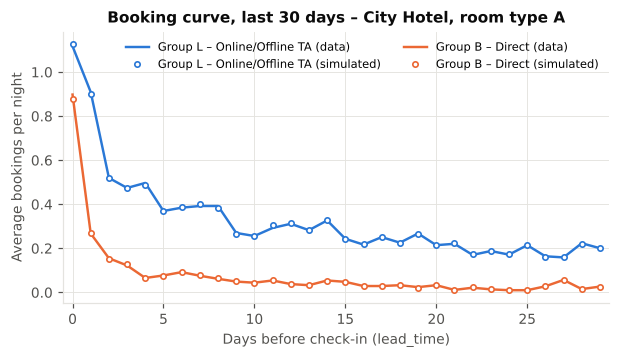

In [10]:
fig_data(show=True)

**Nhận xét.** Hai nhóm khác nhau rõ: nhóm B (Direct) dồn mạnh vào 1–2 ngày cuối và trả giá cao hơn. Đây chính là cơ sở để định giá động có lợi: giữ phòng cho khách đặt muộn trả cao. Các chấm tròn (mô phỏng ở giá lịch sử) trùng với đường dữ liệu, cho thấy bộ mô phỏng được hiệu chỉnh đúng.

## TN2 – So sánh các biến thể Monte Carlo Control

10 seed × 100.000 Episode (mùa bán) cho mỗi phương pháp; đánh giá chính xác bằng DP sau mỗi 1.000 Episode.

In [11]:
def run(make, n_ep=N_EP, every=EVERY):
    L = make(); rows = []
    for k in range(1, n_ep + 1):
        L.run_episode()
        if k % every == 0:
            r, ag = snapshot(L, V0, pi, occ); rows.append((k, r, ag))
    return np.array(rows), np.array(L.revenue, float), L

# ---- TN2: các biến thể MC Control ----
methods = {
    "es":     lambda s: MCExploringStarts(mdp, s),
    "eps01":  lambda s: OnPolicyMC(mdp, s, lambda k: 0.1),
    "glie":   lambda s: OnPolicyMC(mdp, s, lambda k: 1000 / (1000 + k)),
    "offpol": lambda s: OffPolicyMC(mdp, s, eps_b=0.3),
}
for key, mk in methods.items():
    res = [run(lambda: mk(sd)) for sd in SEEDS]
    OUT["c_" + key] = np.stack([r[0] for r in res])
    OUT["rev_" + key] = np.stack([r[1] for r in res])
    if key == "offpol": OUT["tail_offpol"] = np.array([np.mean(r[2].tail) for r in res])
    if key == "eps01": OUT["pi_eps01_seed0"] = np.array(res[0][2].greedy)
    last = OUT["c_" + key][:, -1]
    print(f"TN2 {key:7s} V/V*={last[:,1].mean():.4f}±{last[:,1].std():.4f} agree={last[:,2].mean():.2f} {time.time()-T0:.0f}s", flush=True)

rows = []
for k in ("es", "eps01", "glie", "offpol"):
    last = OUT["c_" + k][:, -1]
    rows.append({"Phương pháp": NAME[k], "Doanh thu / tối ưu (%)": f"{last[:,1].mean()*100:.2f} ± {last[:,1].std()*100:.2f}",
                 "Hơn giá cố định (€)": round((last[:,1].mean() * V0 - max(fixed_vals)), 1),
                 "Khớp π* (theo xác suất ghé thăm, %)": round(last[:,2].mean()*100, 1)})
pd.DataFrame(rows)

TN2 es      V/V*=0.9637±0.0058 agree=0.36 24s


TN2 eps01   V/V*=0.9736±0.0025 agree=0.41 69s


TN2 glie    V/V*=0.9575±0.0044 agree=0.34 115s


TN2 offpol  V/V*=0.9354±0.0063 agree=0.28 152s


,Phương pháp,Doanh thu / tối ưu (%),Hơn giá cố định (€),"Khớp π* (theo xác suất ghé thăm, %)"
0,MC Exploring Starts,96.37 ± 0.58,8.0,36.2
1,"On-policy MC, ε = 0.1",97.36 ± 0.25,18.1,40.6
2,"On-policy MC, GLIE ε = 1000/(1000+k)",95.75 ± 0.44,1.6,33.5
3,"Off-policy MC (weighted IS, b: ε = 0.3)",93.54 ± 0.63,-20.9,28.0


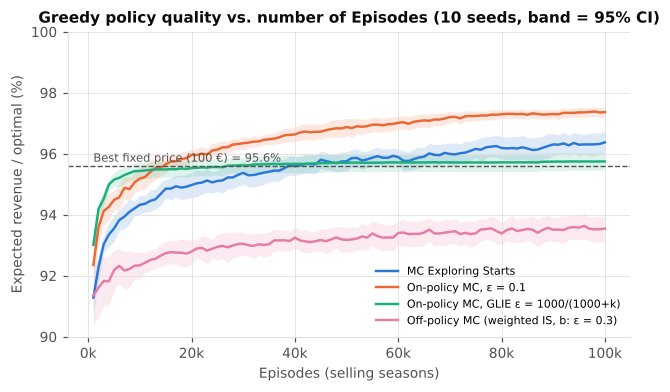

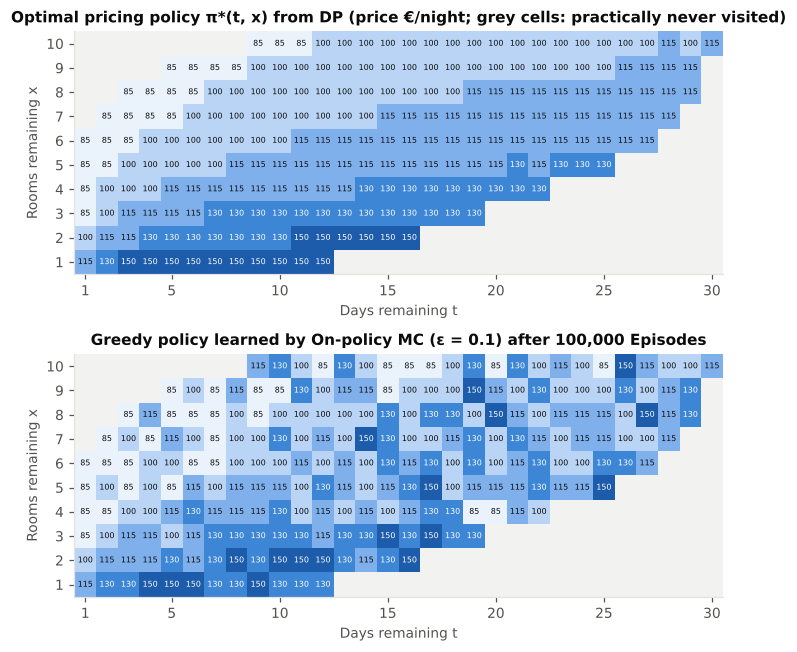

In [12]:
fig_tn2(show=True)
fig_policy(show=True)

## TN0 – Hai hướng cài đặt: NumPy và scikit-learn

scikit-learn không có thuật toán học tăng cường, nhưng **bước đánh giá chính sách** của Monte Carlo là một bài toán hồi quy: mã hóa mỗi cặp (s, a) thành vector one-hot φ(s, a) rồi giải

w* = argmin_w Σᵢ (Gᵢ − w·φ(Sᵢ, Aᵢ))²

Các cột one-hot trực giao nên w*₍ₛ,ₐ₎ đúng bằng **trung bình các Return** tại (s, a), tức ước lượng Monte Carlo. `BatchMC` chạy vòng lặp GPI theo nhịp batch: sinh K = 1.000 Episode ε-greedy, ước lượng lại Q trên toàn bộ dữ liệu (NumPy: `np.bincount`; scikit-learn: `OneHotEncoder` → `Ridge(alpha=1e-10, solver="cholesky")`), rồi cải thiện chính sách greedy. Q được làm tròn 4 chữ số trước `argmax` để hai hướng phá hòa giống nhau (Return là bội số của các mức giá nên hòa tuyệt đối rất thường gặp).

In [13]:
# ----------------------------------------------------------------------------
# 5. Monte Carlo Control dạng batch: hai cách ước lượng Q từ cùng một dữ liệu
# ----------------------------------------------------------------------------
# Ý tưởng: ước lượng Monte Carlo Q(s,a) = trung bình các Return quan sát tại (s,a)
# chính là nghiệm bình phương tối thiểu của bài toán hồi quy G ~ one-hot(s,a).
# - Hướng 1 (không dùng scikit-learn): tính trung bình nhóm bằng np.bincount.
# - Hướng 2 (scikit-learn): OneHotEncoder + hồi quy tuyến tính bình phương tối thiểu (Ridge với α = 1e-10,
#   chỉ để ma trận khả nghịch khi có ô chưa được thăm; sai lệch so với trung bình mẫu < 1e-6).
# Cả hai dùng chung vòng lặp GPI: chạy K Episode theo chính sách ε-greedy hiện tại,
# ước lượng lại Q từ toàn bộ dữ liệu, rồi cải thiện chính sách (greedy theo Q).
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline


class BatchMC(Learner):
    """On-policy Monte Carlo Control dạng batch. estimator='numpy' hoặc 'sklearn'."""

    def __init__(self, mdp, seed, eps=0.1, K=1000, estimator="numpy"):
        super().__init__(mdp, seed)
        self.eps, self.K, self.estimator = eps, K, estimator
        self.n_cells = (mdp.T + 1) * (mdp.C + 1) * mdp.nA
        self.cells, self.returns = [], []
        if estimator == "sklearn":
            self.model = make_pipeline(
                OneHotEncoder(categories=[np.arange(self.n_cells)], sparse_output=True),
                Ridge(alpha=1e-10, fit_intercept=False, solver="cholesky"))
        # chính sách ban đầu: greedy xác định (argmax trên Q = 0 → mức giá đầu tiên) để hai hướng trùng nhau
        self.greedy = [[0] * (mdp.C + 1) for _ in range(mdp.T + 1)]
        self.fit_time = 0.0

    def cell(self, t, x, a):
        return (t * (self.mdp.C + 1) + x) * self.mdp.nA + a

    def run_episode(self):
        self.k += 1
        ep = self.sim.rollout(self.mdp.T, self.mdp.C, lambda t, x: self.eps_act(t, x, self.eps))
        self.revenue.append(sum(e[3] for e in ep))
        G = 0.0
        for t, x, a, r in reversed(ep):
            G += r
            self.cells.append(self.cell(t, x, a)); self.returns.append(G)
        if self.k % self.K == 0:
            self.evaluate_and_improve()

    def estimate_Q(self):
        cells = np.asarray(self.cells); y = np.asarray(self.returns)
        if self.estimator == "numpy":
            cnt = np.bincount(cells, minlength=self.n_cells)
            tot = np.bincount(cells, weights=y, minlength=self.n_cells)
            q = np.divide(tot, cnt, out=np.zeros(self.n_cells), where=cnt > 0)
        else:
            self.model.fit(cells.reshape(-1, 1), y)
            q = self.model[-1].coef_.copy()
        return q.reshape(self.mdp.T + 1, self.mdp.C + 1, self.mdp.nA)

    def evaluate_and_improve(self):
        import time as _t
        t0 = _t.perf_counter(); Qhat = self.estimate_Q(); self.fit_time += _t.perf_counter() - t0
        self.Qhat = Qhat
        g = np.round(Qhat, 4).argmax(axis=2)           # cải thiện chính sách: greedy theo Q
                                                       # (làm tròn 1e-4 € để hai hướng phá hòa giống nhau)
        self.greedy = g.tolist()

In [14]:
# ---- TN0: hai hướng cài đặt – NumPy và scikit-learn ----
K8 = 1000
def run_batch(est, sd):
    L = BatchMC(mdp, sd, eps=0.1, K=K8, estimator=est); rows = []; Qs = []; G = []
    t0 = time.perf_counter()
    for k in range(1, N_EP + 1):
        L.run_episode()
        if k % K8 == 0:
            rows.append((k, mdp.evaluate(L.greedy) / V0)); Qs.append(L.Qhat); G.append(np.array(L.greedy))
    return np.array(rows), Qs, G, time.perf_counter() - t0, L.fit_time
e8 = {"numpy": [], "sklearn": []}; maxdq = 0.0; same = 0; total = 0
for sd in SEEDS:
    a = run_batch("numpy", sd); b = run_batch("sklearn", sd)
    e8["numpy"].append(a); e8["sklearn"].append(b)
    for qa, qb, ga, gb in zip(a[1], b[1], a[2], b[2]):
        maxdq = max(maxdq, float(np.abs(qa - qb).max())); same += int(np.array_equal(ga, gb)); total += 1
    print(f"TN0 seed {sd}: numpy {a[3]:.1f}s (ước lượng {a[4]:.1f}s)  sklearn {b[3]:.1f}s (ước lượng {b[4]:.1f}s)  "
          f"V/V* {a[0][-1,1]:.4f} vs {b[0][-1,1]:.4f}", flush=True)
for est in e8:
    OUT["e8_curve_" + est] = np.stack([r[0] for r in e8[est]])
    OUT["e8_time_" + est] = np.array([r[3] for r in e8[est]]); OUT["e8_fit_" + est] = np.array([r[4] for r in e8[est]])
OUT["e8_maxdq"], OUT["e8_same"], OUT["e8_total"] = maxdq, same, total
print(f"TN0 max|ΔQ|={maxdq:.2e}  chính sách greedy giống hệt ở {same}/{total} lần cải thiện  {time.time()-T0:.0f}s", flush=True)

rows = []
for name, k in (("NumPy – gia tăng (TN2)", "inc"), ("NumPy – batch", "numpy"), ("scikit-learn – batch", "sklearn")):
    c = OUT["c_eps01"] if k == "inc" else OUT["e8_curve_" + k]
    rows.append({"Cách cài đặt": name, "Doanh thu / tối ưu sau 100k (%)": f"{c[:, -1, 1].mean()*100:.2f} ± {c[:, -1, 1].std()*100:.2f}",
                 "Thời gian 100k Episode (s)": "–" if k == "inc" else round(OUT["e8_time_" + k].mean(), 1),
                 "Trong đó ước lượng Q (s)": "–" if k == "inc" else round(OUT["e8_fit_" + k].mean(), 1)})
pd.DataFrame(rows)

TN0 seed 0: numpy 13.7s (ước lượng 11.0s)  sklearn 36.5s (ước lượng 33.5s)  V/V* 0.9769 vs 0.9769


TN0 seed 1: numpy 14.4s (ước lượng 11.5s)  sklearn 35.6s (ước lượng 32.8s)  V/V* 0.9798 vs 0.9798


TN0 seed 2: numpy 14.3s (ước lượng 11.6s)  sklearn 36.8s (ước lượng 33.8s)  V/V* 0.9658 vs 0.9658


TN0 seed 3: numpy 14.6s (ước lượng 12.0s)  sklearn 37.1s (ước lượng 34.1s)  V/V* 0.9754 vs 0.9754


TN0 seed 4: numpy 14.8s (ước lượng 12.1s)  sklearn 37.3s (ước lượng 34.3s)  V/V* 0.9751 vs 0.9751


TN0 seed 5: numpy 14.9s (ước lượng 12.0s)  sklearn 35.5s (ước lượng 32.7s)  V/V* 0.9771 vs 0.9771


... (2 outputs left out)

TN0 seed 8: numpy 16.2s (ước lượng 12.9s)  sklearn 37.3s (ước lượng 34.4s)  V/V* 0.9741 vs 0.9741


TN0 seed 9: numpy 16.5s (ước lượng 13.5s)  sklearn 38.6s (ước lượng 35.6s)  V/V* 0.9721 vs 0.9721


TN0 max|ΔQ|=1.15e-07  chính sách greedy giống hệt ở 1000/1000 lần cải thiện  671s


,Cách cài đặt,Doanh thu / tối ưu sau 100k (%),Thời gian 100k Episode (s),Trong đó ước lượng Q (s)
0,NumPy – gia tăng (TN2),97.36 ± 0.25,–,–
1,NumPy – batch,97.45 ± 0.40,14.9,12.1
2,scikit-learn – batch,97.45 ± 0.40,36.8,33.8


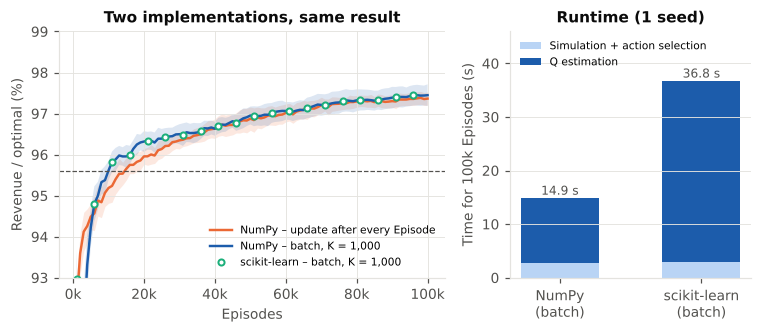

In [15]:
fig_tn8(show=True)

## TN3 – Cái giá của việc học

Regret = doanh thu tối ưu − doanh thu thực thu được trong lúc học, cộng dồn qua các mùa bán.

In [16]:
# ---- TN3: cái giá của việc học (regret) theo ε ----
for e in (0.05, 0.2, 0.3):
    res = [run(lambda: OnPolicyMC(mdp, sd, lambda k, e=e: e)) for sd in SEEDS]
    OUT[f"c_eps{e}"] = np.stack([r[0] for r in res]); OUT[f"rev_eps{e}"] = np.stack([r[1] for r in res])
    print(f"TN3 eps={e} V/V*={OUT[f'c_eps{e}'][:,-1,1].mean():.4f} {time.time()-T0:.0f}s", flush=True)

rows = []
for k, e in (("eps0.05", 0.05), ("eps01", 0.1), ("eps0.2", 0.2), ("eps0.3", 0.3)):
    rev = OUT["rev_" + k]; reg = (V0 - rev).sum(1)
    rows.append({"ε": e, "Doanh thu TB/mùa trong lúc học (€)": round(rev.mean(), 1),
                 "Regret lũy kế 100k mùa (triệu €)": f"{reg.mean()/1e6:.2f} ± {reg.std()/1e6:.2f}",
                 "Chính sách cuối / tối ưu (%)": round(OUT["c_" + k][:, -1, 1].mean() * 100, 2)})
pd.DataFrame(rows)

TN3 eps=0.05 V/V*=0.9706 725s


TN3 eps=0.2 V/V*=0.9799 775s


TN3 eps=0.3 V/V*=0.9816 829s


,ε,Doanh thu TB/mùa trong lúc học (€),Regret lũy kế 100k mùa (triệu €),Chính sách cuối / tối ưu (%)
0,0.05,976.9,4.40 ± 0.29,97.06
1,0.10,977.4,4.35 ± 0.26,97.36
2,0.20,974.8,4.62 ± 0.20,97.99
3,0.30,967.6,5.34 ± 0.14,98.16


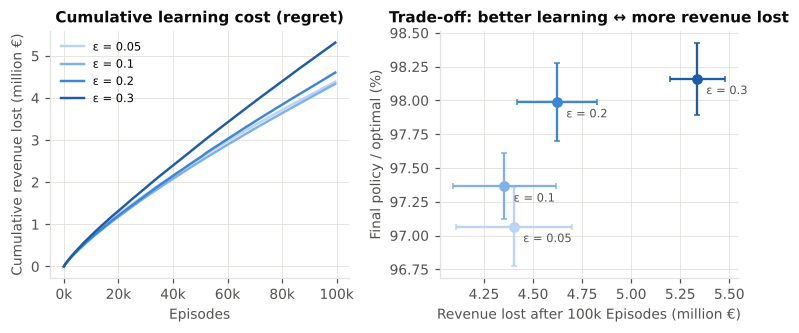

In [17]:
fig_tn3(show=True)

## TN4 – Học từ log giá lịch sử (Off-policy)

Giả sử khách sạn có log 50.000 mùa bán, sinh bởi "quy tắc lịch sử": luôn chào 100 € (gần giá trung vị lịch sử 104 €), nhưng với xác suất ε_b chọn ngẫu nhiên một mức giá. Off-policy MC (weighted IS) học trên log này. Đồng thời thử **đánh giá off-policy** giá trị của π* từ log.

In [18]:
# ---- TN4: học off-policy từ log lịch sử ----
# Behavior: "quy tắc lịch sử" = luôn chào giá a_hist, nhưng với xác suất ε_b chọn ngẫu nhiên đều.
N_LOG = 50_000
pi_star_mat = pi
def log_episode(sim, rng, eps_b):
    probs = []; t, x = mdp.T, mdp.C; ep = []
    while t > 0 and x > 0:
        a = rng.randrange(mdp.nA) if rng.random() < eps_b else a_hist
        pb = eps_b / mdp.nA + (1 - eps_b if a == a_hist else 0)
        t2, x2, r = sim.step(t, x, a); ep.append((t, x, a, r)); probs.append(pb); t, x = t2, x2
    return ep, probs
eps_bs = [0.05, 0.1, 0.3, 0.5, 1.0]
OUT["e4_eps_b"] = eps_bs
q_off = np.zeros((len(eps_bs), 5)); tail = np.zeros((len(eps_bs), 5))
ope_o = np.zeros((len(eps_bs), 5)); ope_w = np.zeros((len(eps_bs), 5)); ess = np.zeros((len(eps_bs), 5))
for i, eb in enumerate(eps_bs):
    for sd in range(5):
        sim = FastPricingSim(mdp, 50_000 + sd); rng = random.Random(60_000 + sd)
        L = OffPolicyMC(mdp, 70_000 + sd)
        swg = sw = sw2 = 0.0
        for n in range(N_LOG):
            ep, probs = log_episode(sim, rng, eb)
            L.learn_from(ep, probs)
            # đánh giá off-policy giá trị của π* từ log
            rho = 1.0; G = 0.0
            for (t, x, a, r), pb in zip(ep, probs):
                G += r; rho *= (1.0 if a == pi_star_mat[t][x] else 0.0) / pb
                if rho == 0: break
            swg += rho * G; sw += rho; sw2 += rho * rho
        q_off[i, sd] = mdp.evaluate(L.greedy) / V0; tail[i, sd] = np.mean(L.tail)
        ope_o[i, sd] = swg / N_LOG; ope_w[i, sd] = swg / sw if sw > 0 else np.nan
        ess[i, sd] = sw * sw / sw2 if sw2 > 0 else 0
    print(f"TN4 eps_b={eb} learned={q_off[i].mean():.4f} tail={tail[i].mean():.3f} ord={ope_o[i].mean():.1f} w={np.nanmean(ope_w[i]):.1f} ess={ess[i].mean():.1f} {time.time()-T0:.0f}s", flush=True)
OUT.update(e4_learned=q_off, e4_tail=tail, e4_ope_o=ope_o, e4_ope_w=ope_w, e4_ess=ess)

pd.DataFrame({"ε_b": eps_bs, "Chính sách học được / tối ưu (%)": np.round(q_off.mean(1) * 100, 2),
              "% bước dùng được để học": np.round(tail.mean(1) * 100, 1),
              "Cỡ mẫu hiệu dụng (ESS) khi đánh giá π* từ 50.000 Episode": np.round(ess.mean(1), 1)})

TN4 eps_b=0.05 learned=0.9598 tail=0.056 ord=0.0 w=nan ess=0.0 834s


/tmp/ipykernel_274/516659481.py:33: RuntimeWarning: Mean of empty slice
  print(f"TN4 eps_b={eb} learned={q_off[i].mean():.4f} tail={tail[i].mean():.3f} ord={ope_o[i].mean():.1f} w={np.nanmean(ope_w[i]):.1f} ess={ess[i].mean():.1f} {time.time()-T0:.0f}s", flush=True)


TN4 eps_b=0.1 learned=0.9527 tail=0.054 ord=0.0 w=nan ess=0.0 840s


TN4 eps_b=0.3 learned=0.9485 tail=0.047 ord=0.0 w=nan ess=0.0 846s


TN4 eps_b=0.5 learned=0.9349 tail=0.046 ord=0.0 w=nan ess=0.0 852s


TN4 eps_b=1.0 learned=0.9253 tail=0.043 ord=0.0 w=nan ess=0.0 860s


,ε_b,Chính sách học được / tối ưu (%),% bước dùng được để học,Cỡ mẫu hiệu dụng (ESS) khi đánh giá π* từ 50.000 Episode
0,0.05,95.98,5.6,0.0
1,0.10,95.27,5.4,0.0
2,0.30,94.85,4.7,0.0
3,0.50,93.49,4.6,0.0
4,1.00,92.53,4.3,0.0


In [19]:
# Xác suất để MỘT Episode dài k bước khớp hoàn toàn với một target xác định
# (target trùng quy tắc lịch sử ở mọi bước: (1 − ε_b + ε_b/5)^k; target khác ở mọi bước: (ε_b/5)^k)
pd.DataFrame({f"ε_b = {e}": {f"khớp quy tắc lịch sử, k={k}": (1 - e + e / 5) ** k for k in (10, 30)} |
              {f"khác quy tắc lịch sử, k={k}": (e / 5) ** k for k in (10, 30)} for e in (0.1, 0.5, 1.0)}).map(lambda v: f"{v:.2e}")

,ε_b = 0.1,ε_b = 0.5,ε_b = 1.0
"khớp quy tắc lịch sử, k=10",4.34e-01,6.05e-03,1.02e-07
"khớp quy tắc lịch sử, k=30",8.20e-02,2.21e-07,1.07e-21
"khác quy tắc lịch sử, k=10",1.02e-17,1.00e-10,1.02e-07
"khác quy tắc lịch sử, k=30",1.07e-51,1.00e-30,1.07e-21


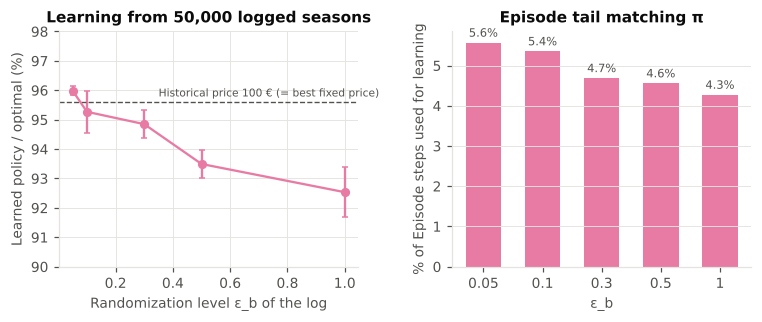

In [20]:
fig_tn4(show=True)

## TN5 – Cú sốc nhu cầu

Sau 30.000 mùa bán, một sự kiện lớn làm nhu cầu tăng gấp đôi. So sánh trung bình mẫu (α = 1/N) với bước cố định α = 0,01 và 0,05.

In [21]:
# ---- TN5: cú sốc nhu cầu (sự kiện lớn làm nhu cầu tăng gấp đôi) ----
sc2 = Scenario(obs, p_hist, demand_mult=2.0); mdp2 = PricingMDP(sc2)
V2, _, pi2 = mdp2.solve(); V20 = V2[mdp2.T, mdp2.C]
OUT["V_shock"] = V20; OUT["V_oldpol_on_shock"] = mdp2.evaluate(pi); OUT["pi_shock"] = pi2
SHOCK, N5 = 30_000, 100_000
def run_shock(L):
    rows = []
    for k in range(1, N5 + 1):
        if k == SHOCK + 1:
            L.mdp = mdp2; L.sim = FastPricingSim(mdp2, 999 + k)
        L.run_episode()
        if k % 1000 == 0:
            ref, m = (V0, mdp) if k <= SHOCK else (V20, mdp2)
            rows.append((k, m.evaluate(L.greedy) / ref))
    return np.array(rows)
for key, mk in {"avg": lambda s: OnPolicyMC(mdp, s, lambda k: 0.1),
                "a001": lambda s: OnPolicyMC(mdp, s, lambda k: 0.1, alpha=0.01),
                "a005": lambda s: OnPolicyMC(mdp, s, lambda k: 0.1, alpha=0.05)}.items():
    OUT["e5_" + key] = np.stack([run_shock(mk(sd)) for sd in SEEDS])
    print(f"TN5 {key} end={OUT['e5_'+key][:,-1,1].mean():.4f} {time.time()-T0:.0f}s", flush=True)

TN5 avg end=0.9289 906s


TN5 a001 end=0.8764 945s


TN5 a005 end=0.9408 986s


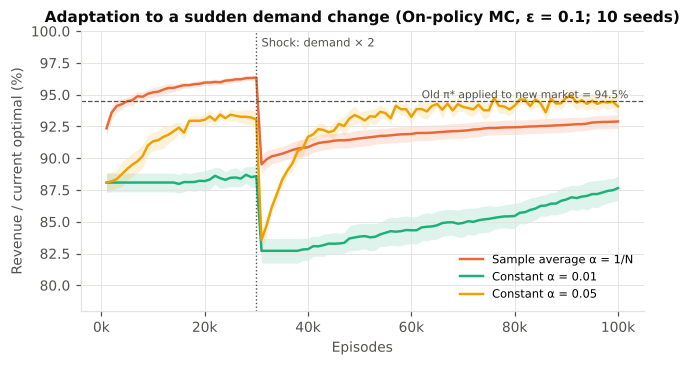

In [22]:
fig_tn5(show=True)

## TN7 – Vì sao Monte Carlo hội tụ chậm ở bài toán này?

In [23]:
# ---- TN7: tỷ lệ tín hiệu/nhiễu và huấn luyện dài ----
sim = FastPricingSim(mdp, 1)
rets = np.array([sum(e[3] for e in sim.rollout(mdp.T, mdp.C, lambda t, x: pi[t][x])) for _ in range(20000)])
gaps = np.array([np.sort(Q[t, x])[-1] - np.sort(Q[t, x])[-2] for t in range(1, mdp.T + 1) for x in range(1, mdp.C + 1)])
wts = np.array([occ[t, x] for t in range(1, mdp.T + 1) for x in range(1, mdp.C + 1)]); wts = wts / wts.sum()
o = np.argsort(gaps); cw = np.cumsum(wts[o])
OUT["snr"] = [rets.mean(), rets.std(), gaps[o][np.searchsorted(cw, 0.5)], gaps[o][np.searchsorted(cw, 0.25)]]
OUT["gaps"], OUT["gap_w"] = gaps, wts
long_rows = []
for sd in range(3):
    L = OnPolicyMC(mdp, sd, lambda k: 0.2); rows = []
    for k in range(1, 1_000_001):
        L.run_episode()
        if k % 50_000 == 0: rows.append((k, mdp.evaluate(L.greedy) / V0))
    long_rows.append(rows)
OUT["long_eps02"] = np.array(long_rows)
print(f"TN7 SNR={OUT['snr']} long end={OUT['long_eps02'][:,-1,1].mean():.4f} {time.time()-T0:.0f}s", flush=True)

ret_mean, ret_sd, gap_med, gap_p25 = OUT["snr"]
print(f"Doanh thu một mùa dưới π*: trung bình {ret_mean:.1f} €, độ lệch chuẩn {ret_sd:.1f} €")
print(f"Chênh lệch Q giữa giá tốt nhất và tốt nhì (trung vị theo xác suất ghé thăm): {gap_med:.2f} €")
print(f"⇒ Để phân biệt với sai số chuẩn bằng nửa khoảng cách cần khoảng (2σ/Δ)² ≈ {(2*ret_sd/gap_med)**2:,.0f} lần thử mỗi cặp (s,a)")

TN7 SNR=[np.float64(1020.8715), np.float64(117.56936458002144), np.float64(0.4491136515772496), np.float64(0.14273218839196034)] long end=0.9928 1131s


Doanh thu một mùa dưới π*: trung bình 1020.9 €, độ lệch chuẩn 117.6 €
Chênh lệch Q giữa giá tốt nhất và tốt nhì (trung vị theo xác suất ghé thăm): 0.45 €
⇒ Để phân biệt với sai số chuẩn bằng nửa khoảng cách cần khoảng (2σ/Δ)² ≈ 274,117 lần thử mỗi cặp (s,a)


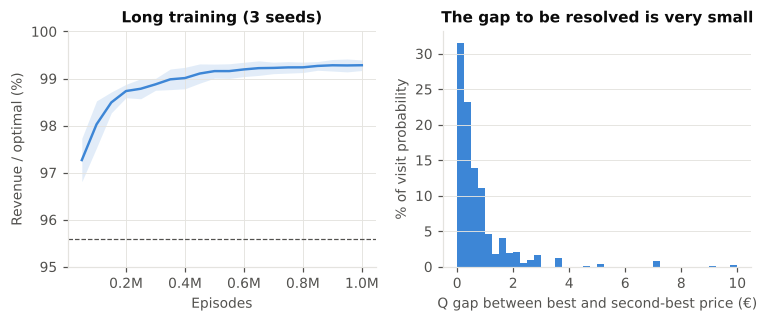

In [24]:
fig_tn7(show=True)

## TN6 – Độ bền với giả định

| Kịch bản | Thay đổi |
|---|---|
| base | σ_L = 0,25; σ_B = 0,5; C = 10 |
| sens_high | Khách nhạy giá hơn: σ_L = 0,15; σ_B = 0,35 |
| late | 30% nhu cầu từ ngày thứ 8 trở đi dồn vào 7 ngày cuối (xu hướng đặt sát ngày) |
| cap15 | Khách sạn còn 15 phòng thay vì 10 |

In [25]:
# ---- TN6: độ bền với giả định ----
scen = {"base": dict(), "sens_high": dict(sigma={"L": 0.15, "B": 0.35}),
        "late": dict(shift_late=0.3), "cap15": dict()}
rows6 = []
for name, kw in scen.items():
    s6 = Scenario(obs, p_hist, **kw); m6 = PricingMDP(s6, C=15 if name == "cap15" else 10)
    V6, _, pi6 = m6.solve(); v6 = V6[m6.T, m6.C]; b6, fv6 = m6.best_fixed()
    occ6 = m6.occupancy(pi6)
    learned = []
    for sd in range(5):
        L = OnPolicyMC(m6, sd, lambda k: 0.1)
        for _ in range(N_EP): L.run_episode()
        learned.append(m6.evaluate(L.greedy) / v6)
    base_pol_val = m6.evaluate(pi) / v6 if name != "cap15" else np.nan
    rows6.append((v6, m6.prices[b6], fv6[b6], np.mean(learned), np.std(learned), base_pol_val))
    print(f"TN6 {name}: V*={v6:.1f} fixed={m6.prices[b6]:.0f}€ {fv6[b6]:.1f} lift={(v6/fv6[b6]-1)*100:.1f}% MC={np.mean(learned):.4f} basepol={base_pol_val:.4f} {time.time()-T0:.0f}s", flush=True)
OUT["e6"] = np.array(rows6); OUT["e6_names"] = list(scen)

e6 = np.array(rows6)
pd.DataFrame({"V* (€)": e6[:,0].round(1), "Giá cố định tốt nhất (€)": e6[:,1].astype(int),
              "Mức tăng của định giá động (%)": ((e6[:,0] / e6[:,2] - 1) * 100).round(1),
              "MC ε=0,1 sau 100k (% tối ưu)": (e6[:,3] * 100).round(2),
              "π* của base áp vào kịch bản (% tối ưu)": (e6[:,5] * 100).round(2)}, index=list(scen))

TN6 base: V*=1021.0 fixed=100€ 976.0 lift=4.6% MC=0.9735 basepol=1.0000 1152s


TN6 sens_high: V*=1010.1 fixed=100€ 984.4 lift=2.6% MC=0.9719 basepol=0.9915 1173s


TN6 late: V*=1019.0 fixed=100€ 976.0 lift=4.4% MC=0.9763 basepol=0.9921 1193s


TN6 cap15: V*=1329.3 fixed=100€ 1286.8 lift=3.3% MC=0.9674 basepol=nan 1214s


,V* (€),Giá cố định tốt nhất (€),Mức tăng của định giá động (%),"MC ε=0,1 sau 100k (% tối ưu)",π* của base áp vào kịch bản (% tối ưu)
base,1021.0,100,4.6,97.35,100.00
sens_high,1010.1,100,2.6,97.19,99.15
late,1019.0,100,4.4,97.63,99.21
cap15,1329.3,100,3.3,96.74,NaN


## Tổng kết

| Câu hỏi | Trả lời ngắn |
|---|---|
| Lợi ích của định giá động | +4,6% doanh thu so với giá cố định tốt nhất (100 €, cũng gần với giá lịch sử) |
| Biến thể MC tốt nhất (100k mùa) | On-policy ε = 0,1: 97,4% tối ưu; ES 96,4%; GLIE 95,8%; Off-policy 93,5% |
| Cái giá của việc học | ε lớn cho chính sách cuối tốt hơn nhưng mất nhiều doanh thu hơn trong lúc học |
| Học từ log lịch sử | Không vượt được giá lịch sử; chỉ khoảng 5% bước trong Episode dùng được |
| Cú sốc nhu cầu | α = 0,05 thích nghi nhanh nhất sau cú sốc, nhưng kém hơn trung bình mẫu khi thị trường ổn định |
| NumPy vs scikit-learn | Cùng Q, cùng chính sách ở mọi lần cải thiện; NumPy nhanh hơn, scikit-learn cho thấy MC là hồi quy trên Return |
| Vì sao chậm | Độ lệch chuẩn doanh thu mùa ≈ 118 €, trong khi chênh lệch cần phân biệt chỉ ≈ 0,45 € |

In [26]:
np.savez_compressed("pricing_results.npz", **{k: np.asarray(v) for k, v in OUT.items() if k != "e6_names"})
print(f"Tổng thời gian: {time.time() - T0:.0f}s")

Tổng thời gian: 1216s
